# Novedad y costo del umbral

**Pregunta:** Con el umbral de reconstrucción preregistrado, ¿qué sensibilidad y tasa de falsas alarmas alcanza el detector OOD?
**Nivel 2 — Análisis aplicado**  
**Prerrequisitos:** nivel 1 y arreglos/logaritmos; 35 min.

## Objetivos

Reconstruya el benchmark CNN congelado sobre observaciones exactas retenidas y cuantifique omisiones del umbral fijo del autoencoder en la cohorte OOD declarada.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

El ledger guarda particiones, errores normalizados, métricas y evaluación OOD separada.

## Método

Detección de novedad usa puntaje y umbral fijado por política de calibración. Sensibilidad TP/(TP+FN), especificidad TN/(TN+FP); alta especificidad puede coexistir con cero detecciones OOD. Evaluación guardada: 160 casos de calibración, 80 OOD, TP=0, FN=80, FP=3, TN=157. Recalcule y grafique los cuatro conteos y ambas tasas, no solo exactitud. No reajuste con etiquetas OOD. Resultado negativo para ese conjunto y umbral, no prueba de que ninguna anomalía sea detectable. La interpretación depende del generador/partición; uso real exige dominios externos independientes y costos operativos calibrados.

El protocolo reconstruye geometría directa, orden de realizaciones, flujo de ruido y normalización registrada antes de puntuar. La salida CNN es una columna integrada, por lo que el error físico no resuelve la posición vertical del cuerpo. El umbral del autoencoder proviene solo de calibración dentro de distribución; las etiquetas OOD describen consecuencias y no deben reajustarlo.

### Qué demuestra el cálculo retenido

El flujo reconstruye el protocolo generador completo en vez de muestrear una miniatura conveniente. Volúmenes completos usan semillas disjuntas por partición; observaciones provienen del mismo operador de sensibilidad gravimétrica. El generador de ruido avanza por particiones previas y el hash debe coincidir con recibo. Así se vinculan geometría, orden, normalización y ruido. Una discrepancia debe detener puntaje, no “arreglarse” buscando semillas de medias parecidas.

La CNN predice contraste de densidad integrado en columna sobre una malla 2D. Sumar blanco sintético 3D en profundidad y multiplicar por espaciamiento vertical produce blanco físico. Error cuadrático tiene unidades de densidad integrada al cuadrado. No evalúa posición vertical ni distingue cuerpos 3D con igual integral. Un puntaje fuerte no prueba modelo terrestre único.

La detección de novedad usa error de reconstrucción normalizado y umbral ID fijado antes de ver etiquetas OOD. Los falsos negativos muestran que error bajo no garantiza geología familiar. Las distribuciones se solapan y AUC queda bajo 0.5 para esta cohorte. Cambiar umbral tras ver OOD invalida prueba preregistrada; la curva de costo es diagnóstico, no reparación posterior.

## Resultados

**Respuesta:** La inferencia CNN reproduce los 160 errores retenidos (MSE normalizado 0.00472348; MSE físico 755.757 frente a 1441.328 clásico). Con umbral 0.0690652, VP/FN/FP/VN = 0/80/3/157.

## Resumen

El umbral fijo omite los 80 casos OOD declarados y produce tres falsas alarmas entre 160 casos de prueba ID. El resultado negativo aplica a este generador y costo, no a todo dominio; aún se requieren cohortes externas representativas.

## Referencias

- Cockett et al. (2018), marco SimPEG, *Geophysical Journal International*, https://doi.org/10.1093/gji/ggy423. Contexto del marco del repositorio; no es el resultado medido.
- Repositorio AI4EPS PhaseNet: https://github.com/AI4EPS/PhaseNet. Proyecto de picks sísmicos incluido en metadatos del repositorio; no se usa en esta inferencia gravimétrica.
- LANL OpenFWI: https://github.com/lanl/OpenFWI. Contexto de benchmark sísmico citado por metadatos; no es entrada de este experimento.


### Diagnóstico 1

Inspeccione el recibo y procedencia del caso.

In [1]:
# Inicializa las importaciones y localiza los datos del repositorio para la lección reservada.
from pathlib import Path
from importlib.metadata import version
import numpy as np
import json
import sys
import torch
import hashlib
import matplotlib.pyplot as plt

root = next(
    p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir() and (p / "data-pipeline").is_dir()
)


### Recalcular las tasas del detector

Los conteos de confusión muestran tanto los casos OOD omitidos como las falsas alarmas en casos retenidos dentro de distribución. Recalcule sensibilidad y especificidad a partir de esos conteos para poder comprobar el punto operativo independientemente de las puntuaciones graficadas. Estas tasas describen este benchmark fijo y no establecen un umbral operativo para datos de campo.

In [2]:
# Recalcule sensibilidad y especificidad a partir de los conteos fijados en el recibo.
# Recalcule las tasas del detector de novedad a partir de los conteos de confusión persistidos.
import json
from pathlib import Path

d = json.loads((root / "data/derived/v2/models/training.json").read_text(encoding="utf-8"))
e = d["novelty_evaluation"]
tp, fn, fp, tn = [e[k] for k in ("true_positive", "false_negative", "false_positive", "true_negative")]
sens = tp / (tp + fn)
spec = tn / (tn + fp)


### Cargue ambas redes congeladas y el operador gravimétrico directo exacto antes de reconstruir las observaciones de prueba. La CNN predice densidad integrada en profundidad, mientras el autoencoder produce una puntuación de reconstrucción para diagnosticar novedad. Los checkpoints son artefactos fijos; las celdas siguientes ejecutan inferencia y la comparan con el registro, sin ajustar pesos nuevos.

In [3]:
print(
    "calibración/OOD",
    e["calibration_count"],
    e["ood_count"],
    "umbral",
    d["novelty_threshold"],
    "VP FN FP VN",
    tp,
    fn,
    fp,
    tn,
    "sensibilidad",
    sens,
    "especificidad",
    spec,
    "AUC",
    e.get("roc_auc"),
)
# Cargue el paquete entrenado comprometido y el operador directo usados en este experimento.
import sys, torch, hashlib

sys.path.insert(0, str(root / "data-pipeline"))
import geology, learning, potential

cnn_model, ae_model, training_meta = learning.load_bundle(root / "data/derived/v2/models")
mesh_real, _, G_real, _ = potential.operators()


calibración/OOD 160 80 umbral 0.0690651684999466 VP FN FP VN 0 80 3 157 sensibilidad 0.0 especificidad 0.98125 AUC 0.361953125


### Diagnóstico 2

Calcule la comparación y grafíquela con unidades físicas.

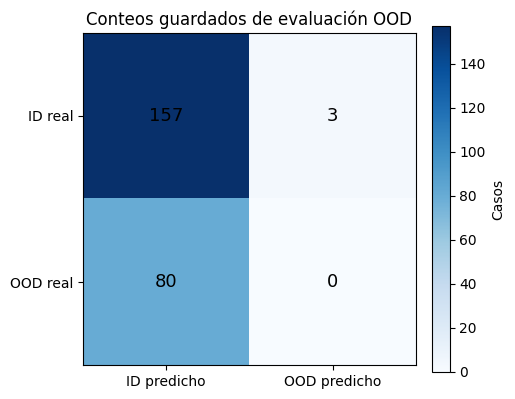

Sensibilidad 0.0 especificidad 0.98125 AUC 0.361953125


In [4]:
# Muestre todos los conteos de confusión para que una especificidad alta no oculte sensibilidad cero.
import matplotlib.pyplot as plt

mat = np.array([[tn, fp], [fn, tp]])
fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
im = ax.imshow(mat, cmap="Blues")
ax.set(
    xticks=[0, 1],
    xticklabels=["ID predicho", "OOD predicho"],
    yticks=[0, 1],
    yticklabels=["ID real", "OOD real"],
    title="Conteos guardados de evaluación OOD",
)
for (i, j), v in np.ndenumerate(mat):
    ax.text(j, i, str(v), ha="center", va="center", fontsize=13)
fig.colorbar(im, ax=ax, label="Casos")
plt.show()
print("Sensibilidad", sens, "especificidad", spec, "AUC", e.get("roc_auc"))


### Experimento: política de umbral y consecuencias OOD

La regla almacenada elige el percentil 99 de los errores de reconstrucción de calibración **in-distribution**, antes de examinar el conjunto OOD. Recalcule las consecuencias en los percentiles 90, 95 y 99 de calibración. Para cada umbral, informe la fracción de falsas alarmas en calibración y la sensibilidad OOD, pero no elija el umbral usando etiquetas OOD. Este análisis controlado de puntos de operación usa las puntuaciones guardadas; no crea otro detector ni afirma representar geologías naturales. Un conteo alto de verdaderos negativos puede ocultar sensibilidad OOD casi nula: informe ambas tasas y sus tamaños de muestra.

In [5]:
# Ejecute el experimento documentado con la evidencia del repositorio.
cal = np.asarray(e["calibration_errors"], float)
ood = np.asarray(e["ood_test_errors"], float)
assert len(cal) == e["calibration_count"] and len(ood) == e["ood_count"]
print("cuantil | umbral | falsas alarmas de calibración | sensibilidad OOD (solo evaluación)")
operating = []
for q in (0.90, 0.95, 0.99):
    threshold = float(np.quantile(cal, q))
    fpr = float(np.mean(cal > threshold))
    tpr = float(np.mean(ood > threshold))
    operating.append((q, threshold, fpr, tpr))
    print(f"{q:.0%} | {threshold:.6g} | {fpr:.3f} | {tpr:.3f}")
print(
    ("La fila del percentil 99 es la política preregistrada. "
     "Las tasas OOD describen consecuencias, no la selección.")
)


cuantil | umbral | falsas alarmas de calibración | sensibilidad OOD (solo evaluación)
90% | 0.0202868 | 0.100 | 0.013
95% | 0.0463008 | 0.050 | 0.000
99% | 0.0690652 | 0.013 | 0.000
La fila del percentil 99 es la política preregistrada. Las tasas OOD describen consecuencias, no la selección.


### Cargar el modelo entrenado y la geometría directa

El checkpoint se carga desde el paquete de entrenamiento comprometido y su SHA-256 se verifica. El operador directo y la arquitectura deben coincidir con el ledger. Este es el modelo entrenado real, no una red de demostración sin entrenar.


In [6]:
# Compruebe la identidad del checkpoint cargado y las dimensiones físicas del operador directo.
cnn_sha = training_meta["models"]["cnn"]["sha256"]
print("Checkpoint CNN", cnn_sha, "sondeo", training_meta["survey_shape"], "G", G_real.shape)


Checkpoint CNN efdd5d4661ddadfeeeb6709eb42336b0cd91ade25548f119c1fbd3d6698c3125 sondeo [32, 32] G (1024, 10752)


### Reconstruir entradas de prueba retenidas

El benchmark usa realizaciones completas y la semilla de prueba registrada. Reconstruir esos blancos y observaciones directas exactos hace auditable la entrada de inferencia. Son casos sintéticos retenidos, no mediciones de campo.


In [7]:
# Regenere los 160 volúmenes de prueba y observaciones gravimétricas exactos a partir de la semilla del registro.
test_models = learning.generate(mesh_real.cell_centers, 160, training_meta["seeds"][2])
test_clean = test_models @ G_real.T
print("modelos de prueba y observaciones limpias", test_models.shape, test_clean.shape)


modelos de prueba y observaciones limpias (160, 10752) (160, 1024)


### Verificar la realización de ruido

El ruido de entrenamiento, validación y prueba comparte un flujo aleatorio sembrado; se avanza por particiones previas antes de reproducir prueba. La verificación hash impide llamar real a una reconstrucción solo parecida.


In [8]:
# Avance el flujo de ruido documentado a través de entrenamiento y validación antes de la prueba.
noise_rng = np.random.default_rng(5001)
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (800, G_real.shape[0]))
noise_rng.normal(0, 0.02 * training_meta["input_scale"], (160, G_real.shape[0]))
test_noise = noise_rng.normal(0, 0.02 * training_meta["input_scale"], test_clean.shape)
test_input = test_clean + test_noise
test_sha = hashlib.sha256(test_input.astype("<f8").tobytes()).hexdigest()
assert test_sha == training_meta["comparison"]["noisy_test_sha256"]
print("SHA-256 de entrada retenida verificado", test_sha)


SHA-256 de entrada retenida verificado 75fee10c9c19cff26ae51a02258ddd24c1958bf812c8b445abb3881e35b29940


### Ejecutar inferencia CNN retenida

La CNN congelada mapea observaciones gravimétricas normalizadas a densidad integrada en una columna 2D. La verdad volumétrica sintética se suma en profundidad para crear el blanco comparable. No es una inversión 3D y prueba no actualiza pesos.


In [9]:
# Infiera el objetivo de densidad integrada en profundidad con las observaciones retenidas exactas y con ruido.
from geology import VOLUME_SHAPE, VOLUME_SPACING

x_test = torch.as_tensor(
    test_input / training_meta["input_scale"], dtype=torch.float32, device=next(cnn_model.parameters()).device
).reshape(-1, 1, *training_meta["survey_shape"])
y_test = test_models.reshape(-1, *VOLUME_SHAPE).sum(1) * VOLUME_SPACING[2] / training_meta["target_scale"]
with torch.no_grad():
    pred_test = cnn_model(x_test).cpu().numpy()
cnn_errors = np.mean((pred_test - y_test) ** 2, axis=(1, 2))
print("casos inferidos", len(cnn_errors), "MSE normalizado medio", float(cnn_errors.mean()))


casos inferidos 160 MSE normalizado medio 0.004723478481682726


### Comparar inferencia con el recibo

Los errores por caso vuelven a unidades físicas cuadradas y se cotejan con el ledger comprometido. La concordancia verifica conjuntamente carga, normalización, orden y entradas. El baseline clásico y CNN usan idénticas observaciones; la conclusión depende del generador sintético.


In [10]:
# Reconstruya los errores pareados de la CNN en unidades físicas y verifique cada caso de prueba registrado.
cnn_mse_physical = cnn_errors * training_meta["target_scale"] ** 2
recorded_cnn = np.asarray(training_meta["models"]["cnn"]["test_errors"]) * training_meta["target_scale"] ** 2
assert np.allclose(cnn_mse_physical, recorded_cnn, rtol=2e-4, atol=2e-4)
classical_mse = np.asarray(training_meta["classical_test_errors"])
print("MSE físico de CNN", float(cnn_mse_physical.mean()), "clásico", float(classical_mse.mean()))


MSE físico de CNN 755.7565570692364 clásico 1441.3277421693124


### Ejecutar inferencia OOD del autoencoder

El autoencoder congelado puntúa una familia OOD sembrada por separado con el umbral fijado solo en calibración. Las etiquetas OOD informan consecuencias y no seleccionan el umbral. Los falsos negativos permanecen; error de reconstrucción no es detector universal.


In [11]:
# Evalúe la familia OOD independiente con el autoencoder congelado y el umbral fijo.
ood_models = learning.generate_ood(mesh_real.cell_centers, 80, 59001)
ood_clean = ood_models @ G_real.T
ood_input = ood_clean + np.random.default_rng(59002).normal(
    0, 0.02 * training_meta["input_scale"], ood_clean.shape
)
x_ood = torch.as_tensor(
    ood_input / training_meta["input_scale"], dtype=torch.float32, device=next(ae_model.parameters()).device
).reshape(-1, 1, *training_meta["survey_shape"])
with torch.no_grad():
    score_ood = (ae_model(x_ood) - x_ood).square().flatten(1).mean(1).cpu().numpy()
score_id = np.asarray(training_meta["novelty_evaluation"]["id_test_errors"])
threshold = training_meta["novelty_threshold"]
tp = int(np.sum(score_ood > threshold))
fn = len(score_ood) - tp
fp = int(np.sum(score_id > threshold))
tn = len(score_id) - fp
print("umbral", threshold, "VP FN FP VN", tp, fn, fp, tn)


umbral 0.0690651684999466 VP FN FP VN 0 80 3 157


### Graficar errores pareados retenidos

Cada punto compara MSE CNN y clásico en la misma realización sintética. Debajo de la diagonal favorece CNN y encima favorece el método clásico. El gráfico no demuestra transferencia a campo ni recuperación de estructura en profundidad.


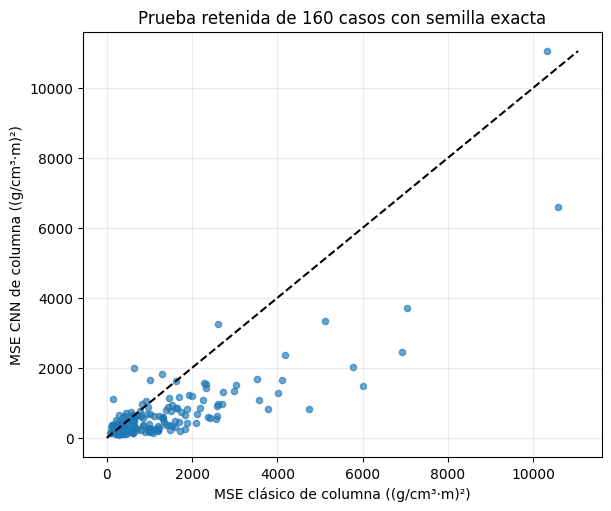

In [12]:
# Compare cada caso retenido de la CNN con la base clásica de la misma entrada.
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
ax.scatter(classical_mse, cnn_mse_physical, s=20, alpha=0.65)
lim = max(float(classical_mse.max()), float(cnn_mse_physical.max()))
ax.plot([0, lim], [0, lim], "k--")
ax.set(
    xlabel="MSE clásico de columna ((g/cm³·m)²)",
    ylabel="MSE CNN de columna ((g/cm³·m)²)",
    title="Prueba retenida de 160 casos con semilla exacta",
)
ax.grid(alpha=0.25)
plt.show()


### Error CNN frente a la línea base clásica

Cada punto compara los errores MSE de ambos métodos para la misma columna reservada; la diagonal discontinua marca igualdad. Los puntos sobre la diagonal indican menor error CNN y los inferiores, menor error clásico, siempre según los ejes etiquetados. La nube permite ver si la ventaja aparece de forma consistente o depende de unas pocas columnas, algo que el promedio oculta. Esta figura evalúa las 160 entradas sintéticas de este recibo con semillas exactas; no mide incertidumbre geofísica, casos de campo ni rendimiento fuera de la familia generadora. El solapamiento con la diagonal limita cualquier conclusión a una comparación pareada en este conjunto.

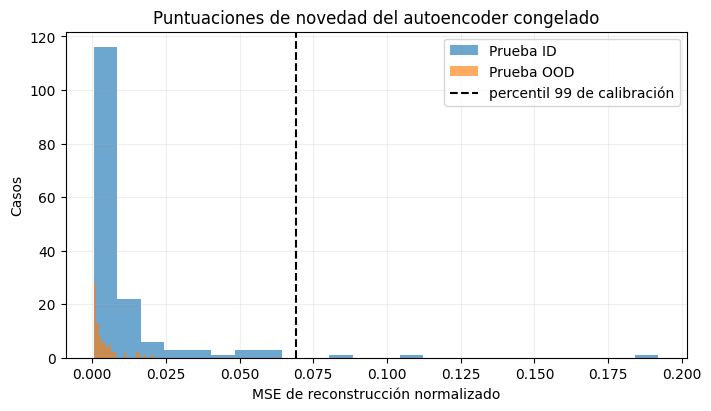

In [13]:
# Muestre el umbral de reconstrucción fijo frente a las puntuaciones de prueba ID y OOD.
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
ax.hist(score_id, bins=24, alpha=0.65, label="Prueba ID")
ax.hist(score_ood, bins=24, alpha=0.65, label="Prueba OOD")
ax.axvline(threshold, color="black", ls="--", label="percentil 99 de calibración")
ax.set(xlabel="MSE de reconstrucción normalizado", ylabel="Casos", title="Puntuaciones de novedad del autoencoder congelado")
ax.legend()
ax.grid(alpha=0.2)
plt.show()


### Puntajes de novedad y umbral congelado

Las distribuciones muestran los errores de reconstrucción ID y OOD reservados; la línea vertical es el percentil 99 calculado solo con calibración ID. El amplio solapamiento explica por qué este umbral deja pasar los 80 ejemplos OOD y marca falsamente tres de los 160 controles ID, según la matriz de confusión de arriba. El histograma describe este autoencoder, esta normalización y esta familia OOD sintética; no demuestra detección de anomalías geológicas ni permite escoger un umbral nuevo mirando las etiquetas de prueba. La inferencia válida es una baja sensibilidad OOD en este experimento cerrado.

### Recargar la CNN mediante la API de checkpoints

El cargador del bundle ya comprueba metadatos y hashes. Esta llamada pública independiente reconstruye la arquitectura con la forma del ledger y lee la ruta exacta del checkpoint; la igualdad de parámetros confirma que la inferencia no dependió de pesos alterados en memoria.


In [14]:
# Recargue la CNN congelada y compare sus parámetros con el modelo usado.
cnn_entry = training_meta["models"]["cnn"]
cnn_path = root / "data/derived/v2/models" / Path(cnn_entry["checkpoint"]).name
cnn_reloaded = learning.load_checkpoint(
    learning.InverseCNN(input_shape=tuple(training_meta["survey_shape"])), cnn_path
).to(next(cnn_model.parameters()).device)
cnn_reload_error = max(
    float((left - right).abs().max().detach().cpu())
    for left, right in zip(cnn_model.parameters(), cnn_reloaded.parameters(), strict=True)
)
assert cnn_reload_error == 0.0
print("diferencia máxima al recargar CNN", cnn_reload_error)


diferencia máxima al recargar CNN 0.0


### Medir la columna retenida en unidades físicas

Aplique la métrica de recuperación del repositorio a la inferencia exacta y a la verdad integrada. RMSE y razón frente al modelo cero resumen solo el objetivo de columna; la CNN no devuelve un volumen de densidad resuelto en profundidad.


In [15]:
# Aplique la métrica física compartida a la inferencia exacta retenida.
from evaluation import model_metrics

physical_prediction = pred_test * training_meta["target_scale"]
physical_truth = y_test * training_meta["target_scale"]
heldout_recovery = model_metrics(physical_prediction, physical_truth)
print("RMSE físico de columna", heldout_recovery["model_rmse"])
print("razón frente a base", heldout_recovery["baseline_ratio"])


RMSE físico de columna 27.491026845187832
razón frente a base 0.36162633287599516
